# GUM — raw vs STAC folder vs cloud

Checks that the GUM layer is the same in the three places it lives:

1. **Raw**: `P:\...\Data_Vivian\GUM_v1.0.shp` (original shapefile)
2. **STAC folder**: `P:\...\Data_Vivian\stac\gum\parquet\gum.parquet` (GeoParquet produced by `notebooks/24_gum.ipynb`)
3. **Cloud**: the GeoParquet found through the public STAC catalog (`gca-stac-7`, collection `gum`)

There are too many features (911 551 polygons with 10 attribute columns) to draw three times, so the check is split in two:

- **Whole world / whole layer, attributes only:** all attribute columns are compared (rows, values) and the key column `OBJECTID` is checked.
- **One region, geometries:** the features inside `BBOX` are read from each source, plotted side by side and compared geometry by geometry.

Environment: `environment_exploration.yml` (Miniforge). Reading the raw shapefile and the cloud columns takes a few minutes.

In [7]:
import tempfile
from pathlib import Path
from posixpath import join as urljoin

import fsspec
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import pyogrio
import pystac_client
from pyproj import CRS, Transformer

## 1) Locations

In [8]:
data_vivian = Path(r"P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian")
raw_path = data_vivian / "GUM_v1.0.shp"
stac_folder_path = data_vivian / "stac" / "gum" / "parquet" / "gum.parquet"

gcs_protocol = "https://storage.googleapis.com"
catalog_url = urljoin(gcs_protocol, "gca-data-public", "gca", "gca-stac-7", "catalog.json")
collection_id = "gum"

KEY = "OBJECTID"  # unique id column, used to put the rows of the three sources in the same order
GEOM_TOLERANCE = 0  # degrees; 0 = exact (raw is already EPSG:4326), > 0 when the raw data has to be reprojected

# Region used for the geometry check (west, south, east, north): Nile delta, Egypt
BBOX = (30.0, 29.5, 32.5, 31.7)

for p in (raw_path, stac_folder_path):
    print(p.is_file(), p)

True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\GUM_v1.0.shp
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\gum\parquet\gum.parquet


## 2) Find the data through the STAC catalog

In [9]:
catalog = pystac_client.Client.open(catalog_url)
collection = next((c for c in catalog.get_children() if c.id == collection_id), None)
if collection is None:
    raise LookupError(f"Collection {collection_id} not found in {catalog_url}")

items = list(collection.get_items())
print("Collection:", collection.id, "|", collection.title)
print("Items:", [i.id for i in items])

item = items[0]
assert collection_id in item.assets["data"].href, f"Unexpected item href: {item.assets['data'].href}"
cloud_href = item.assets["data"].href
print("Cloud GeoParquet:", cloud_href)
print("Item bbox:", item.bbox)
print("table:row_count:", item.properties.get("table:row_count"))

# Attribute columns from the parquet schema (no data is read), independent of the item's table:columns
attr_cols = [n for n in pq.read_schema(stac_folder_path).names if n not in ("geometry", "bbox")]
item_cols = [c["name"] for c in item.properties.get("table:columns", [])]
if item_cols:
    print("item table:columns match the parquet schema:", set(item_cols) - {"bbox"} == set(attr_cols) | {"geometry"})
else:
    print("WARNING: the cloud item has no table:columns (re-run scripts/24_gum.ipynb steps 4-7)")
print("Attribute columns:", attr_cols)

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\client.py:191: NoConformsTo: Server does not advertise any conformance classes.
  warnings.warn(NoConformsTo())


Collection: gum | GUM – Global Unconsolidated Sediment Map Database
Items: ['gum']
Cloud GeoParquet: https://storage.googleapis.com/gca-data-public/gca/gum/gum.parquet
Item bbox: [-179.999981, -89.985257, 179.999986, 83.589292]
table:row_count: 911551
item table:columns match the parquet schema: True
Attribute columns: ['OBJECTID', 'Symbol', 'Descriptio', 'XX', 'YY', 'ZZ', 'AA', 'DD', 'Shape_Leng', 'Shape_Area']


c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


## 3) Read the attributes of the whole layer

Geometries are skipped; only the attribute columns are read from the three sources.

In [10]:
def tidy(df: pd.DataFrame) -> pd.DataFrame:
    return df[attr_cols].sort_values(KEY).reset_index(drop=True)


tables = {}
tables["raw (P:)"] = tidy(pyogrio.read_dataframe(raw_path, read_geometry=False, encoding="utf-8"))
tables["stac folder (P:)"] = tidy(pq.read_table(stac_folder_path, columns=attr_cols).to_pandas())
with fsspec.open(cloud_href).open() as f:
    tables["cloud (catalog)"] = tidy(pq.read_table(f, columns=attr_cols).to_pandas())

pd.DataFrame(
    {
        name: {
            "rows": len(df),
            f"unique {KEY}": df[KEY].is_unique,
            "columns": len(df.columns),
        }
        for name, df in tables.items()
    }
).T

,rows,unique OBJECTID,columns
raw (P:),911551,True,10
stac folder (P:),911551,True,10
cloud (catalog),911551,True,10


## 4) Compare the attributes

In [11]:
names = list(tables)
ref = names[0]
attr_results = []
for other in names[1:]:
    same_shape = tables[ref].shape == tables[other].shape
    identical = same_shape and tables[ref].equals(tables[other])
    n_diff = int((tables[ref].ne(tables[other]) & ~(tables[ref].isna() & tables[other].isna())).to_numpy().sum()) if same_shape else None
    attr_results.append({"comparison": f"{ref} vs {other}", "same shape": same_shape, "different values": n_diff, "identical": identical})
display(pd.DataFrame(attr_results))

if all(r["identical"] for r in attr_results):
    print("OK: raw, stac folder and cloud have exactly the same attribute table.")
else:
    print("MISMATCH: see the table above.")

,comparison,same shape,different values,identical
0,raw (P:) vs stac folder (P:),True,0,True
1,raw (P:) vs cloud (catalog),True,0,True


OK: raw, stac folder and cloud have exactly the same attribute table.


## 5) Read the features inside `BBOX`

The shapefile has no spatial index, so it is scanned once in chunks (Arrow) and the features that touch the box are kept and **cached in the temp folder** (`gca_check_cache`): the first run reads the whole file, later runs are instant. The GeoParquet files are read through the `bbox` covering column. The raw features are reprojected to EPSG:4326 if needed, and all three sources are then filtered with the same exact bounds test so that the boundary is treated identically. If the sources still differ, the features that differ are listed with their bounds.

In [12]:
west, south, east, north = BBOX

# BBOX in the CRS of the shapefile (a lon/lat box is a rectangle in the cylindrical/Mercator CRS, plus a small pad)
raw_crs = CRS.from_user_input(pyogrio.read_info(raw_path)["crs"])
if raw_crs.to_epsg() == 4326:
    raw_bbox = BBOX
else:
    to_raw = Transformer.from_crs(4326, raw_crs, always_xy=True)
    (x0, y0), (x1, y1) = to_raw.transform(west, south), to_raw.transform(east, north)
    pad = 50_000  # m, generous: the in_bbox test below trims the result exactly
    raw_bbox = (min(x0, x1) - pad, min(y0, y1) - pad, max(x0, x1) + pad, max(y0, y1) + pad)
print("raw CRS:", raw_crs.name, "| raw bbox:", raw_bbox)


def in_bbox(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    b = gdf.geometry.bounds
    return gdf[(b.maxx >= west) & (b.minx <= east) & (b.maxy >= south) & (b.miny <= north)]


# A shapefile has no spatial index, so a bbox filter reads the whole file anyway (and is slow over P:).
# Scan it once in chunks with Arrow, keep the features that touch raw_bbox and cache that subset in the temp folder,
# so that re-running the notebook is fast. The OGR bbox filter is not used: the exact test is in_bbox() below.
CACHE_DIR = Path(tempfile.gettempdir()) / "gca_check_cache"
CACHE_DIR.mkdir(exist_ok=True)
stat = raw_path.stat()
cache_path = CACHE_DIR / f"{collection_id}_{'_'.join(f'{v:.0f}' for v in raw_bbox)}_{stat.st_size}_{int(stat.st_mtime)}.parquet"


def read_raw_in_bbox(path, bbox, chunk=250_000):
    n_total = pyogrio.read_info(path)["features"]
    xmin, ymin, xmax, ymax = bbox
    parts = []
    for start in range(0, n_total, chunk):
        part = pyogrio.read_dataframe(path, skip_features=start, max_features=chunk, use_arrow=True)
        b = part.geometry.bounds
        parts.append(part[(b.maxx >= xmin) & (b.minx <= xmax) & (b.maxy >= ymin) & (b.miny <= ymax)])
        print(f"  {min(start + chunk, n_total):,} / {n_total:,} features scanned", end="\r")
    print()
    return pd.concat(parts, ignore_index=True)


if cache_path.is_file():
    raw = gpd.read_parquet(cache_path)
    print("raw subset read from the cache:", cache_path)
else:
    raw = read_raw_in_bbox(raw_path, raw_bbox)
    raw.to_parquet(cache_path)
    print("raw subset cached in:", cache_path)
if raw.crs.to_epsg() != 4326:
    raw = raw.to_crs(4326)

regions = {}
regions["raw (P:)"] = raw
regions["stac folder (P:)"] = gpd.read_parquet(stac_folder_path, bbox=BBOX)
regions["cloud (catalog)"] = gpd.read_parquet(cloud_href, bbox=BBOX, filesystem=fsspec.filesystem("https"))

# Drop the covering column, apply the same bounds test and put the rows in the same order
regions = {
    name: in_bbox(gdf.drop(columns="bbox", errors="ignore")).sort_values(KEY).reset_index(drop=True)
    for name, gdf in regions.items()
}
for name, gdf in regions.items():
    print(f"{name}: {len(gdf)} features, crs={gdf.crs.to_string()}")

# If the sources disagree, show which features differ and where they lie relative to BBOX
ref_name = list(regions)[0]
for name in list(regions)[1:]:
    only_ref = regions[ref_name][~regions[ref_name][KEY].isin(regions[name][KEY])]
    only_other = regions[name][~regions[name][KEY].isin(regions[ref_name][KEY])]
    if len(only_ref) or len(only_other):
        print(f"\n{ref_name} vs {name}: {len(only_ref)} only in {ref_name}, {len(only_other)} only in {name}")
        for label, df in ((ref_name, only_ref), (name, only_other)):
            if len(df):
                print(f"  only in {label}:")
                print(df.assign(minx=df.bounds.minx, miny=df.bounds.miny, maxx=df.bounds.maxx, maxy=df.bounds.maxy)[[KEY, "minx", "miny", "maxx", "maxy"]].to_string(index=False))


raw CRS: WGS 84 | raw bbox: (30.0, 29.5, 32.5, 31.7)
  911,551 / 911,551 features scanned
raw subset cached in: C:\Users\fuentesm\AppData\Local\Temp\gca_check_cache\gum_30_30_32_32_1890990900_1790197712.parquet
raw (P:): 446 features, crs=EPSG:4326
stac folder (P:): 446 features, crs=EPSG:4326
cloud (catalog): 446 features, crs=EPSG:4326


## 6) Plot the features

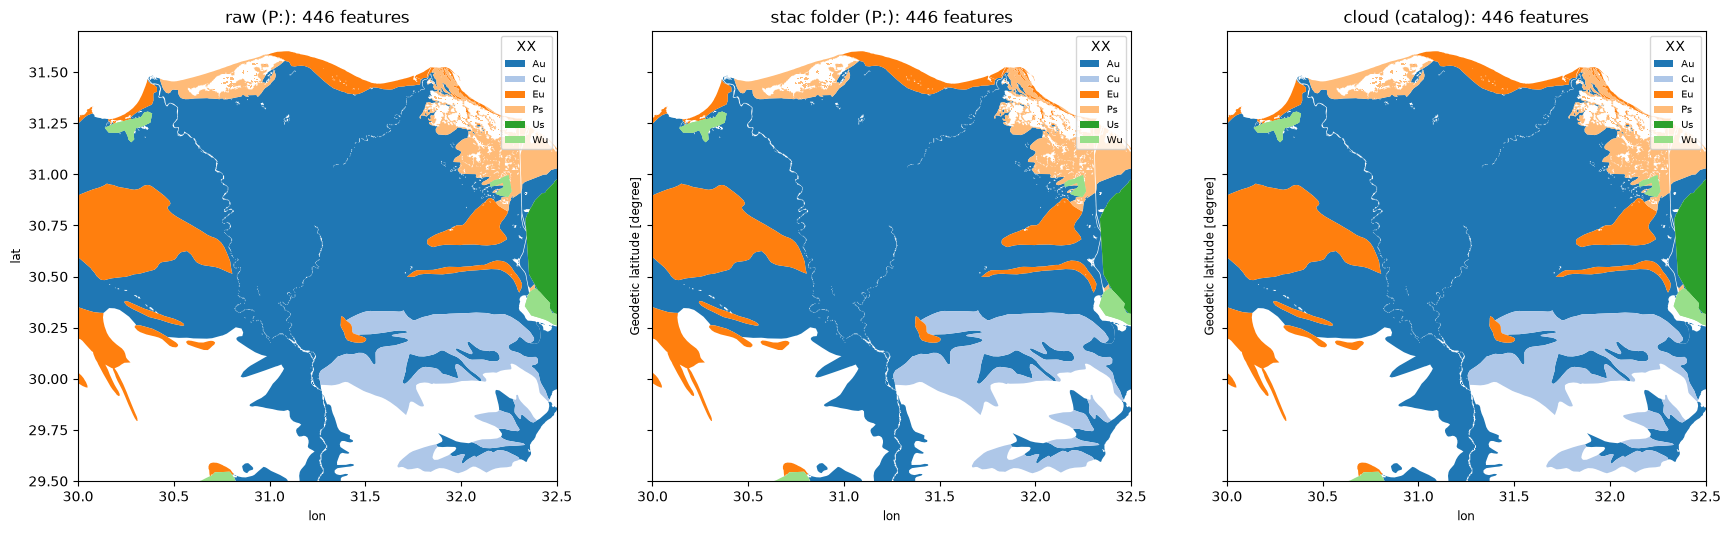

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharex=True, sharey=True)
for ax, (name, gdf) in zip(axes, regions.items()):
    gdf.plot(ax=ax, column="XX", categorical=True, cmap="tab20", legend=True, legend_kwds={"title": "XX", "fontsize": 7})
    ax.set_xlim(BBOX[0], BBOX[2])
    ax.set_ylim(BBOX[1], BBOX[3])
    ax.set_title(f"{name}: {len(gdf)} features")
    ax.set_xlabel("lon")
axes[0].set_ylabel("lat")
plt.show()

## 7) Compare the geometries

In [14]:
ref = list(regions)[0]
geom_results = []
for other in list(regions)[1:]:
    same_ids = regions[ref][KEY].equals(regions[other][KEY])
    a = pd.DataFrame(regions[ref].drop(columns="geometry"))
    b = pd.DataFrame(regions[other].drop(columns="geometry"))
    attr_issues = []
    if set(a.columns) != set(b.columns):
        attr_issues.append(f"columns only in {ref}: {sorted(set(a.columns) - set(b.columns))}; only in {other}: {sorted(set(b.columns) - set(a.columns))}")
    if same_ids:
        for col in [c for c in a.columns if c in b.columns]:
            x, y = a[col].reset_index(drop=True), b[col].reset_index(drop=True)
            if pd.api.types.is_numeric_dtype(x) and pd.api.types.is_numeric_dtype(y):
                bad = ~(np.isclose(x.astype(float), y.astype(float), rtol=1e-6, atol=0, equal_nan=True))
            else:
                bad = ~((x.astype(str) == y.astype(str)) | (x.isna() & y.isna()))
            if bad.any():
                i = int(bad.idxmax())
                attr_issues.append(f"{col}: {int(bad.sum())} rows differ, e.g. {ref}={x[i]!r} vs {other}={y[i]!r} (dtypes {x.dtype} / {y.dtype})")
    same_attrs = same_ids and not attr_issues
    if attr_issues:
        print(f"{ref} vs {other}: attribute differences")
        for msg in attr_issues:
            print("  -", msg)
    n_diff = int((~regions[ref].geometry.geom_equals_exact(regions[other].geometry, tolerance=GEOM_TOLERANCE)).sum()) if same_ids else None
    geom_results.append({
        "comparison": f"{ref} vs {other}",
        "same features": same_ids,
        "same attributes": same_attrs,
        "same CRS": regions[ref].crs == regions[other].crs,
        "different geometries": n_diff,
        "identical": bool(same_attrs and n_diff == 0),
    })
display(pd.DataFrame(geom_results))

if all(r["identical"] for r in geom_results):
    print("OK: raw, stac folder and cloud contain the same features in BBOX.")
else:
    print("MISMATCH: see the table above.")

,comparison,same features,same attributes,same CRS,different geometries,identical
0,raw (P:) vs stac folder (P:),True,True,True,0,True
1,raw (P:) vs cloud (catalog),True,True,True,0,True


OK: raw, stac folder and cloud contain the same features in BBOX.
